
# Estimating Human Ratings from Face Images

### Machine Learning Project | Neural Ninjas

## 1. Introduction

This project aims to estimate the average human rating associated with a face image using classical machine learning techniques.

The project uses the SCUT-FBP5500 dataset, which contains face images and corresponding human-assigned ratings.

Image processing techniques are used to extract meaningful numerical features from the images. These features are then used to train and evaluate different regression models.

## 2. Objectives

- Understand and audit the image-rating dataset.
- Analyse the distribution of human ratings and disagreement between raters.
- Extract different representations of image features.
- Compare classical machine learning regression algorithms.
- Evaluate model performance, stability, and generalisation.
- Analyse prediction errors and limitations.
- Develop a reusable pipeline for predicting ratings on unseen images.

## 3. Project Scope

This project focuses on traditional machine learning and handcrafted image features. Deep learning methods are not included.

## 4. Dataset

**Dataset:** SCUT-FBP5500

**Task:** Supervised Regression

**Input:** Face Images

**Target:** Average Human Rating (1–5)


In [1]:

# Import required libraries

import os
import json
import time
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import skimage
from skimage.feature import hog

import sklearn
from sklearn.model_selection import (
    train_test_split,
    KFold,
    RepeatedKFold,
    cross_validate,
    learning_curve,
    GroupShuffleSplit
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_regression

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error
)

import joblib

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

print("\nLibrary versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-image:", skimage.__version__)
print("Scikit-learn:", sklearn.__version__)


All libraries imported successfully!

Library versions:
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-image: 0.25.2
Scikit-learn: 1.6.1


In [2]:
# Check the current working directory

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in the current directory:")

for item in os.listdir():
    print(item)

Current working directory:
/content

Files and folders in the current directory:
.config
sample_data


## Dataset Setup

We use the SCUT-FBP5500 dataset released by South China University of Technology.

The dataset contains 5,500 face images and corresponding human-assigned ratings.

Instead of uploading the dataset manually, we will download it directly into the Google Colab environment. We will then extract the files and inspect the dataset structure.

In [5]:
# Download the official SCUT-FBP5500 dataset

!pip -q install gdown

import gdown
import zipfile

dataset_zip = "/content/SCUT-FBP5500.zip"
dataset_folder = "/content/SCUT-FBP5500"

file_id = "1w0TorBfTIqbquQVd6k3h_77ypnrvfGwf"

gdown.download(
    id=file_id,
    output=dataset_zip,
    quiet=False
)

# Extract the downloaded dataset

with zipfile.ZipFile(dataset_zip, "r") as zip_ref:
    zip_ref.extractall(dataset_folder)

print("\nDataset downloaded and extracted successfully!")
print("Dataset location:", dataset_folder)

Downloading...
From (original): https://drive.google.com/uc?id=1w0TorBfTIqbquQVd6k3h_77ypnrvfGwf
From (redirected): https://drive.google.com/uc?id=1w0TorBfTIqbquQVd6k3h_77ypnrvfGwf&confirm=t&uuid=17d56472-e64d-4571-8ce3-517aaaeb81f4
To: /content/SCUT-FBP5500.zip
100%|██████████| 180M/180M [00:00<00:00, 235MB/s]



Dataset downloaded and extracted successfully!
Dataset location: /content/SCUT-FBP5500


## Exploring the Dataset Structure

Before analysing the dataset, we need to understand how its files are organised.

We will inspect the extracted directories, identify image files and locate the rating annotation files.

This step helps us establish the correct file paths for all subsequent analysis.

In [6]:
# Inspect the dataset folder structure

dataset_path = Path("/content/SCUT-FBP5500")

for root, dirs, files_list in os.walk(dataset_path):
    level = root.replace(str(dataset_path), "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{Path(root).name}/")

    for filename in files_list[:10]:
        print(f"{indent}    {filename}")

    if len(files_list) > 10:
        print(f"{indent}    ... and {len(files_list) - 10} more files")

SCUT-FBP5500/
    SCUT-FBP5500_v2/
        train_test_files.zip
        README.txt
        All_Ratings.xlsx
        Images_Sources.xlsx
        Images/
            CM67.jpg
            CM217.jpg
            AF408.jpg
            CF230.jpg
            AM1472.jpg
            AM1161.jpg
            AF1845.jpg
            CM659.jpg
            AF1948.jpg
            AM1469.jpg
            ... and 5490 more files
        train_test_files/
            All_labels.txt
        facial landmark/
            AM1090.pts
            AM6.pts
            AM1139.pts
            AM797.pts
            AF1423.pts
            CM159.pts
            AF381.pts
            AF178.pts
            AF442.pts
            AM1287.pts
            ... and 5490 more files


## Understanding the Rating Annotations

The dataset provides human-assigned ratings for each face image.

Before defining our prediction target, we need to examine the annotation files and understand:
- How individual ratings are stored.
- Whether multiple ratings are available for each image.
- How image filenames are linked to their ratings.
- What information is provided in the dataset documentation.

This will help us choose an appropriate target for regression.

In [7]:
# Define the main dataset paths

data_root = dataset_path / "SCUT-FBP5500_v2"

images_path = data_root / "Images"
ratings_file = data_root / "All_Ratings.xlsx"
labels_file = data_root / "train_test_files" / "All_labels.txt"
readme_file = data_root / "README.txt"

# Read the dataset documentation

with open(readme_file, "r", encoding="utf-8", errors="ignore") as file:
    readme_text = file.read()

print("DATASET README")
print("=" * 60)
print(readme_text[:4000])

# Load the ratings spreadsheet once

ratings_df = pd.read_excel(ratings_file)

print("\n\nRATINGS FILE")
print("=" * 60)
print("Shape:", ratings_df.shape)
print("Columns:", ratings_df.columns.tolist())
display(ratings_df.head())

# Inspect the label file

print("\n\nLABEL FILE")
print("=" * 60)

with open(labels_file, "r", encoding="utf-8", errors="ignore") as file:
    for _ in range(10):
        line = file.readline()
        if not line:
            break
        print(line.rstrip())

DATASET README
README
--------------------------
(1) Folder "Images" contains 5500 frontal, unoccluded faces aged from 15 to 60 with neutral expression. It can be divided into four subsets with different races and gender, including 2000 Asian females, 2000 Asian males, 750 Caucasian females and 750 Caucasian males.

(2) SheetAll_Ratings.xlsxincludes the ratings of 60 volunteers. All the images are labeled with beauty scores ranging from [1, 5] by totally 60 volunteers. "original Rating" representa the previous rating of some raters who was randomly equired to rate some of the images again.

(3) Folder "train_test_files" contains the training and testing files. There are two kinds of validation ways, including: 1)5-folds cross validations (for each validation, 80% samples are used for training and the rest for testing); 2)the split of 60% training and 40% testing (60% samples are used for training and the rest for testing). 

(4) Folder "facial landmark" contains the landmark files of 5

,Rater,Filename,Rating,original Rating
0,1,CF1.jpg,3,NaN
1,1,CF10.jpg,3,NaN
2,1,CF100.jpg,1,NaN
3,1,CF101.jpg,2,NaN
4,1,CF102.jpg,3,NaN




LABEL FILE
CF437.jpg 2.883333
AM1384.jpg 2.466667
AM1234.jpg 2.15
AM1774.jpg 3.75
CF215.jpg 3.033333
AF1899.jpg 2.916667
AM704.jpg 2.483333
AM1172.jpg 2.266667
CM434.jpg 3.033333
CF228.jpg 2.75


## Initial Dataset Audit

We will perform an initial audit to understand the size, completeness, and structure of the dataset.

The audit will examine:
- Total number of face images and rating records.
- Number of unique raters and images.
- Rating range and missing values.
- Number of ratings available per image.
- Repeated ratings and duplicate annotation records.
- Consistency between image filenames and rating annotations.

These checks will help us identify data-quality issues before feature extraction and model training.

In [8]:
# Count available image files

image_files = sorted([
    file.name for file in images_path.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

# Load the provided average-rating label file

labels_df = pd.read_csv(
    labels_file,
    sep=r"\s+",
    header=None,
    names=["Filename", "Label"]
)

# Basic dataset information

print("DATASET SUMMARY")
print("=" * 50)
print("Total image files:", len(image_files))
print("Total rating records:", len(ratings_df))
print("Unique images in ratings:", ratings_df["Filename"].nunique())
print("Unique raters:", ratings_df["Rater"].nunique())
print("Records in label file:", len(labels_df))

# Rating information

print("\nRATING INFORMATION")
print("=" * 50)
print("Minimum rating:", ratings_df["Rating"].min())
print("Maximum rating:", ratings_df["Rating"].max())
print("Missing ratings:", ratings_df["Rating"].isna().sum())
print("Missing filenames:", ratings_df["Filename"].isna().sum())

# Ratings available per image

ratings_per_image = ratings_df.groupby("Filename")["Rating"].count()

print("\nRATINGS PER IMAGE")
print("=" * 50)
print(ratings_per_image.describe())

# Repeated ratings and duplicate records

print("\nREPEATED RATING INFORMATION")
print("=" * 50)
print("Non-missing original ratings:",
      ratings_df["original Rating"].notna().sum())

print("Duplicate annotation rows:",
      ratings_df.duplicated().sum())

print("Repeated rater-image pairs:",
      ratings_df.duplicated(subset=["Rater", "Filename"]).sum())

# Check whether image files and annotations match

image_set = set(image_files)
rating_image_set = set(ratings_df["Filename"].dropna())
label_image_set = set(labels_df["Filename"].dropna())

print("\nFILE CONSISTENCY")
print("=" * 50)
print("Images without rating records:", len(image_set - rating_image_set))
print("Rating filenames without images:", len(rating_image_set - image_set))
print("Images without label records:", len(image_set - label_image_set))
print("Label filenames without images:", len(label_image_set - image_set))

DATASET SUMMARY
Total image files: 5500
Total rating records: 330000
Unique images in ratings: 5500
Unique raters: 60
Records in label file: 5500

RATING INFORMATION
Minimum rating: 1
Maximum rating: 5
Missing ratings: 0
Missing filenames: 0

RATINGS PER IMAGE
count    5500.0
mean       60.0
std         0.0
min        60.0
25%        60.0
50%        60.0
75%        60.0
max        60.0
Name: Rating, dtype: float64

REPEATED RATING INFORMATION
Non-missing original ratings: 38500
Duplicate annotation rows: 0
Repeated rater-image pairs: 0

FILE CONSISTENCY
Images without rating records: 0
Rating filenames without images: 0
Images without label records: 0
Label filenames without images: 0


## Defining the Prediction Target

Each image has 60 ratings provided by different human evaluators. Since the task is a regression problem, we need to combine these individual ratings into a single target value for each image.

We will compare two aggregation methods:

1. Mean Rating: The arithmetic average of the 60 ratings.
2. Median Rating: The middle value of the 60 ratings after sorting them.

The mean rating will be used as the primary prediction target, while the median will help us examine the effect of different aggregation methods.

We will also calculate the standard deviation and interquartile range to measure disagreement among human evaluators.

The resulting target represents an aggregate of subjective human opinions, not an objective measure of a person's appearance or worth.

In [9]:
# Calculate rating statistics for each image

image_targets = ratings_df.groupby("Filename")["Rating"].agg(
    Mean_Rating="mean",
    Median_Rating="median",
    Rating_Std="std",
    Rating_Min="min",
    Rating_Max="max",
    Rating_Count="count"
)

# Calculate interquartile range

rating_quartiles = ratings_df.groupby("Filename")["Rating"].quantile(
    [0.25, 0.75]
).unstack()

image_targets["Rating_IQR"] = (
    rating_quartiles[0.75] - rating_quartiles[0.25]
)

# Reset index for easier use

image_targets = image_targets.reset_index()

# Display the results

print("Target dataset shape:", image_targets.shape)

display(image_targets.head())

print("\nOverall target statistics:")
display(image_targets[[
    "Mean_Rating",
    "Median_Rating",
    "Rating_Std",
    "Rating_IQR"
]].describe().round(3))

Target dataset shape: (5500, 8)


,Filename,Mean_Rating,Median_Rating,Rating_Std,Rating_Min,Rating_Max,Rating_Count,Rating_IQR
0,AF1.jpg,2.333333,2.0,0.680644,1,3,60,1.0
1,AF10.jpg,3.433333,3.0,0.592800,2,4,60,1.0
2,AF100.jpg,2.900000,3.0,0.439568,1,4,60,0.0
3,AF1000.jpg,3.966667,4.0,0.712281,2,5,60,0.0
4,AF1001.jpg,3.733333,4.0,0.841038,2,5,60,1.0



Overall target statistics:


,Mean_Rating,Median_Rating,Rating_Std,Rating_IQR
count,5500.000,5500.000,5500.000,5500.000
mean,2.991,3.057,0.643,0.727
std,0.688,0.706,0.088,0.453
min,1.017,1.000,0.129,0.000
25%,2.500,3.000,0.591,0.250
50%,2.833,3.000,0.647,1.000
75%,3.533,3.500,0.700,1.000
max,4.750,5.000,1.081,2.000


## Validating the Prediction Target

The dataset also provides a separate file containing an average rating for each image.

To verify our target calculation, we will compare the mean ratings calculated from the 60 individual evaluations with the values in this provided label file.

This check helps confirm that our selected target is consistent with the dataset's supplied annotations.

In [10]:
# Compare our calculated mean ratings with the provided labels

target_validation = image_targets.merge(
    labels_df,
    on="Filename",
    how="inner"
)

target_validation["Difference"] = (
    target_validation["Mean_Rating"] - target_validation["Label"]
).abs()

print("Number of matched images:", len(target_validation))
print("Mean absolute difference:",
      target_validation["Difference"].mean())
print("Maximum absolute difference:",
      target_validation["Difference"].max())

# Check whether the values match within a small tolerance

matching = np.isclose(
    target_validation["Mean_Rating"],
    target_validation["Label"],
    atol=1e-5
)

print("\nMatching ratings:", matching.sum())
print("Non-matching ratings:", (~matching).sum())

display(
    target_validation[
        ["Filename", "Mean_Rating", "Label", "Difference"]
    ].head()
)

Number of matched images: 5500
Mean absolute difference: 2.197575757397258e-07
Maximum absolute difference: 3.33333333379926e-07

Matching ratings: 5500
Non-matching ratings: 0


,Filename,Mean_Rating,Label,Difference
0,AF1.jpg,2.333333,2.333333,3.333333e-07
1,AF10.jpg,3.433333,3.433333,3.333333e-07
2,AF100.jpg,2.900000,2.900000,0.000000e+00
3,AF1000.jpg,3.966667,3.966667,3.333333e-07
4,AF1001.jpg,3.733333,3.733333,3.333333e-07


## Analysing Rating Distribution and Disagreement

Before extracting image features, we will examine how the human ratings are distributed.

We will visualise:
- The distribution of average ratings across all images.
- The variation in ratings given by different evaluators.
- The relationship between average ratings and evaluator disagreement.

These visualisations will help us understand the target values and identify images where human opinions differ considerably.

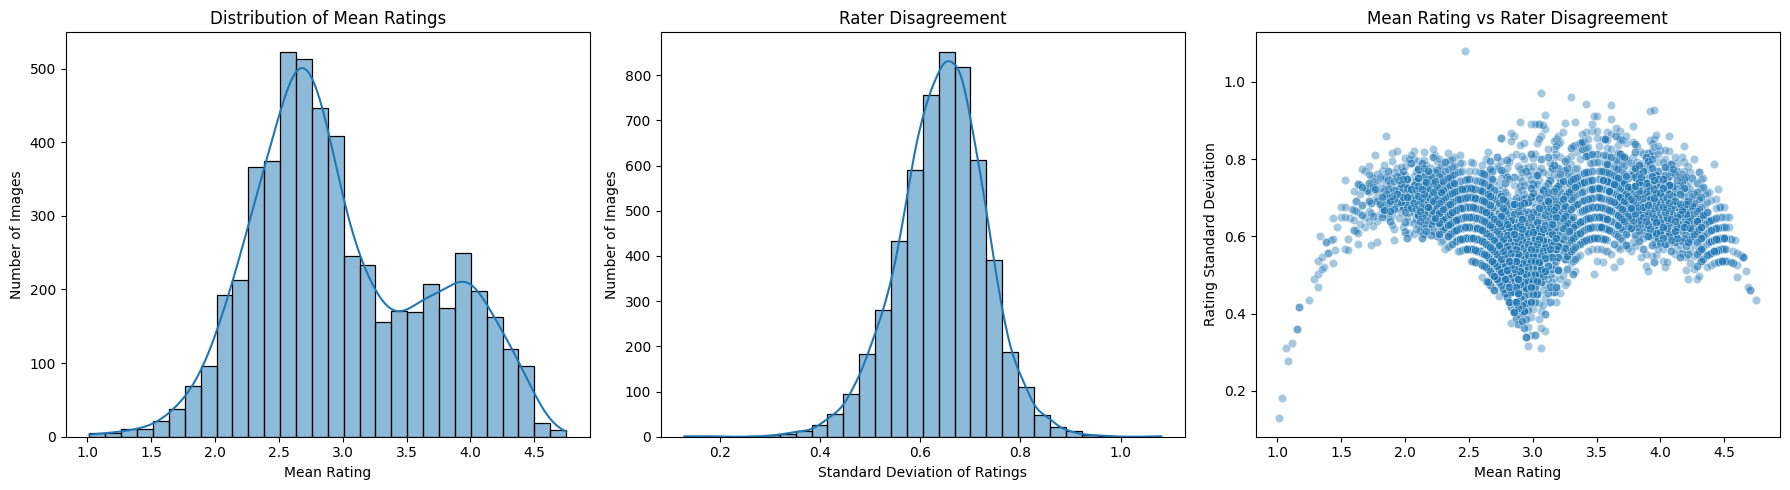

In [11]:
# Plot rating distribution and rater disagreement

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of mean ratings

sns.histplot(
    image_targets["Mean_Rating"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Mean Ratings")
axes[0].set_xlabel("Mean Rating")
axes[0].set_ylabel("Number of Images")

# 2. Distribution of rating standard deviation

sns.histplot(
    image_targets["Rating_Std"],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Rater Disagreement")
axes[1].set_xlabel("Standard Deviation of Ratings")
axes[1].set_ylabel("Number of Images")

# 3. Mean rating vs disagreement

sns.scatterplot(
    data=image_targets,
    x="Mean_Rating",
    y="Rating_Std",
    alpha=0.4,
    ax=axes[2]
)
axes[2].set_title("Mean Rating vs Rater Disagreement")
axes[2].set_xlabel("Mean Rating")
axes[2].set_ylabel("Rating Standard Deviation")

plt.tight_layout()
plt.show()

## Image Quality and Duplicate Audit

Before extracting features, we need to check whether the image files are suitable for processing.

We will examine:
- Image dimensions and colour modes.
- Corrupted or unreadable image files.
- Images with unusual dimensions.
- Exact duplicate images using file hashes.

Duplicate images can affect model evaluation if identical copies appear in both training and testing sets. Identifying them before splitting the data helps reduce the risk of data leakage.

In [12]:
# Audit image dimensions, formats, and duplicate files

image_records = []
image_hashes = {}

for filename in image_files:
    image_file = images_path / filename

    try:
        # Read image information
        with Image.open(image_file) as img:
            width, height = img.size
            mode = img.mode
            image_format = img.format
            img.verify()

        # Calculate file hash
        with open(image_file, "rb") as file:
            file_hash = hashlib.sha256(file.read()).hexdigest()

        image_records.append({
            "Filename": filename,
            "Width": width,
            "Height": height,
            "Mode": mode,
            "Format": image_format,
            "Status": "Valid",
            "Hash": file_hash
        })

        image_hashes[filename] = file_hash

    except Exception:
        image_records.append({
            "Filename": filename,
            "Width": None,
            "Height": None,
            "Mode": None,
            "Format": None,
            "Status": "Corrupted",
            "Hash": None
        })

# Store audit results

image_audit_df = pd.DataFrame(image_records)

# Display audit summary

print("IMAGE QUALITY AUDIT")
print("=" * 45)

print("Total images checked:", len(image_audit_df))
print("Valid images:", (image_audit_df["Status"] == "Valid").sum())
print("Corrupted images:", (image_audit_df["Status"] == "Corrupted").sum())

print("\nImage dimensions:")
display(
    image_audit_df.groupby(["Width", "Height"]).size()
    .reset_index(name="Number of Images")
    .head(10)
)

print("\nImage colour modes:")
display(image_audit_df["Mode"].value_counts())

# Identify exact duplicate files

duplicate_hashes = image_audit_df[
    image_audit_df["Hash"].notna()
].groupby("Hash").filter(lambda group: len(group) > 1)

print("\nDUPLICATE IMAGE CHECK")
print("=" * 45)
print("Images belonging to duplicate groups:", len(duplicate_hashes))
print("Number of duplicate groups:", duplicate_hashes["Hash"].nunique())

if len(duplicate_hashes) > 0:
    display(duplicate_hashes[["Filename", "Hash"]].head(20))

IMAGE QUALITY AUDIT
Total images checked: 5500
Valid images: 5500
Corrupted images: 0

Image dimensions:


,Width,Height,Number of Images
0,350,350,5500



Image colour modes:


,count
Mode,
RGB,5500



DUPLICATE IMAGE CHECK
Images belonging to duplicate groups: 0
Number of duplicate groups: 0


## Visual Inspection of Sample Images

We will display a small sample of face images along with their average ratings.

This helps us understand the input data before converting images into numerical features.

We will also compare images with different rating levels to observe how subjective ratings are distributed across the dataset.

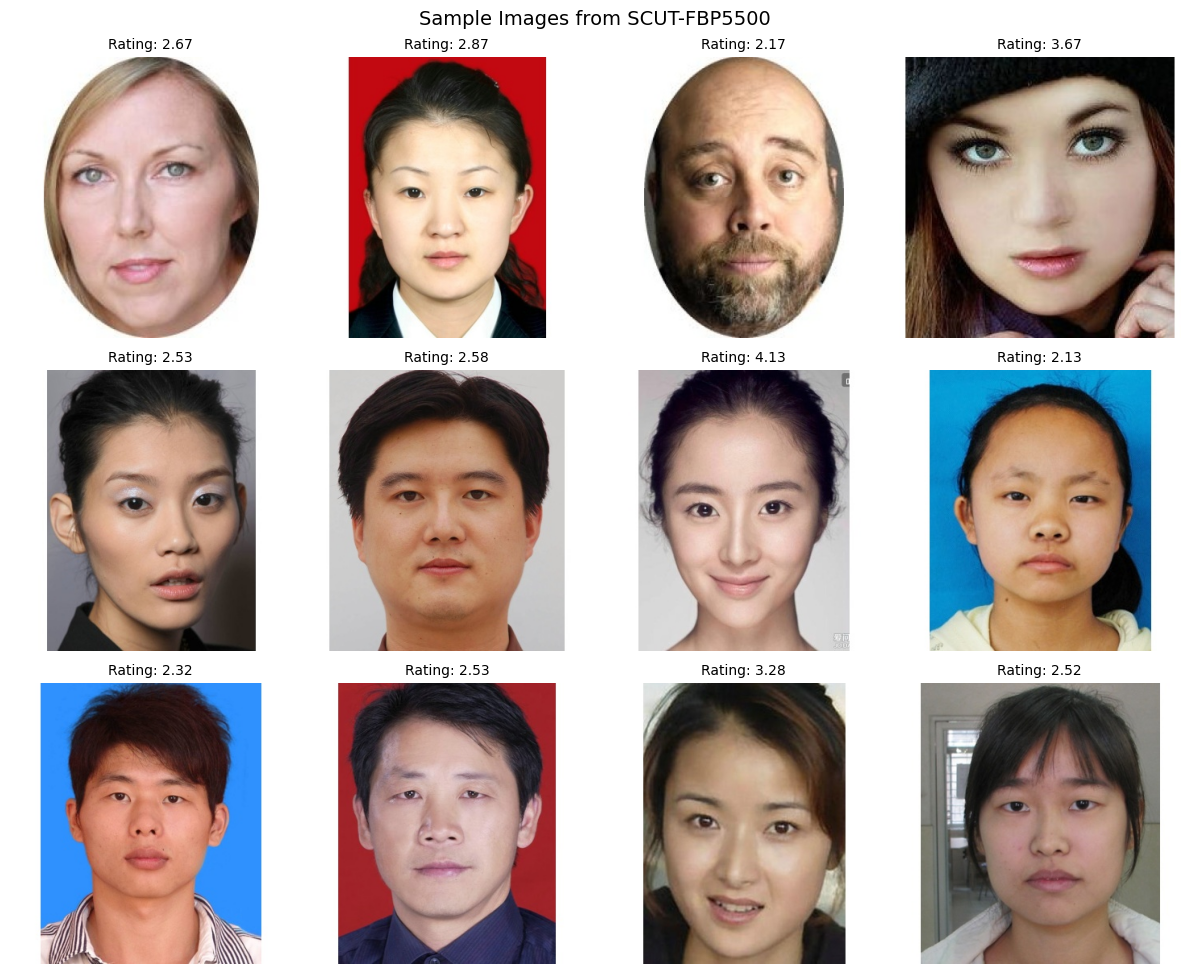

In [13]:
# Display a sample of images with their average ratings

sample_images = image_targets.sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):
    image_path = images_path / row["Filename"]

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(
        f"Rating: {row['Mean_Rating']:.2f}",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle("Sample Images from SCUT-FBP5500", fontsize=14)
plt.tight_layout()
plt.show()

## Feature Extraction Using HOG

Histogram of Oriented Gradients (HOG) is a traditional image feature extraction technique.

It describes the shapes and edges present in an image by calculating the distribution of gradient directions in small image regions.

For this project, we will:
- Convert each image to grayscale.
- Resize it to 128 × 128 pixels.
- Extract HOG features using 9 orientations.
- Use 8 × 8 pixels per cell and 2 × 2 cells per block.

HOG captures local shape and edge information but does not preserve colour information or understand facial features semantically.

We will store the extracted features in a numerical array for use in regression models.

In [14]:
# Extract HOG features from all images

hog_features = []

start_time = time.time()

for i, filename in enumerate(image_targets["Filename"]):

    image_path = images_path / filename

    with Image.open(image_path) as img:
        img = img.convert("L")
        img = img.resize((128, 128))
        image_array = np.array(img)

    features = hog(
        image_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    hog_features.append(features.astype(np.float32))

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1} of {len(image_targets)} images")

# Convert features into a NumPy array

X_hog = np.array(hog_features, dtype=np.float32)

hog_time = time.time() - start_time

print("\nHOG feature extraction completed!")
print("Feature matrix shape:", X_hog.shape)
print("Number of images:", X_hog.shape[0])
print("Features per image:", X_hog.shape[1])
print("Extraction time:", round(hog_time, 2), "seconds")
print("Feature storage:",
      round(X_hog.nbytes / (1024 ** 2), 2), "MB")

Processed 500 of 5500 images
Processed 1000 of 5500 images
Processed 1500 of 5500 images
Processed 2000 of 5500 images
Processed 2500 of 5500 images
Processed 3000 of 5500 images
Processed 3500 of 5500 images
Processed 4000 of 5500 images
Processed 4500 of 5500 images
Processed 5000 of 5500 images
Processed 5500 of 5500 images

HOG feature extraction completed!
Feature matrix shape: (5500, 8100)
Number of images: 5500
Features per image: 8100
Extraction time: 66.37 seconds
Feature storage: 169.94 MB


##  Feature Extraction Using RGB Colour Histograms

Our second image representation uses RGB colour histograms.

A colour histogram describes how pixel intensities are distributed across the red, green, and blue channels.

For each image, we will:
- Resize the image to 128 × 128 pixels.
- Separate its red, green, and blue channels.
- Calculate a histogram with 32 bins for each channel.
- Normalise the histograms so that they represent proportions rather than image size.

This produces 96 features per image (32 features for each of the three colour channels).

Unlike HOG, this representation captures colour information but does not describe the spatial arrangement of objects or facial structures.

In [15]:
# Extract RGB colour histogram features from all images

color_features = []

start_time = time.time()

for i, filename in enumerate(image_targets["Filename"]):

    image_path = images_path / filename

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize((128, 128))
        image_array = np.array(img)

    image_histograms = []

    # Calculate a normalised histogram for each RGB channel
    for channel in range(3):
        histogram, _ = np.histogram(
            image_array[:, :, channel],
            bins=32,
            range=(0, 256),
            density=True
        )

        image_histograms.extend(histogram)

    color_features.append(image_histograms)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1} of {len(image_targets)} images")

# Convert features into a NumPy array

X_color = np.array(color_features, dtype=np.float32)

color_time = time.time() - start_time

print("\nRGB histogram extraction completed!")
print("Feature matrix shape:", X_color.shape)
print("Number of images:", X_color.shape[0])
print("Features per image:", X_color.shape[1])
print("Extraction time:", round(color_time, 2), "seconds")
print("Feature storage:",
      round(X_color.nbytes / (1024 ** 2), 2), "MB")

Processed 500 of 5500 images
Processed 1000 of 5500 images
Processed 1500 of 5500 images
Processed 2000 of 5500 images
Processed 2500 of 5500 images
Processed 3000 of 5500 images
Processed 3500 of 5500 images
Processed 4000 of 5500 images
Processed 4500 of 5500 images
Processed 5000 of 5500 images
Processed 5500 of 5500 images

RGB histogram extraction completed!
Feature matrix shape: (5500, 96)
Number of images: 5500
Features per image: 96
Extraction time: 29.25 seconds
Feature storage: 2.01 MB


## Comparison of Image Feature Representations

We have extracted two different numerical representations from the SCUT-FBP5500 images.

1. HOG features capture local edges, gradients, and shape information.
2. RGB colour histograms capture the distribution of colour intensities.

We will compare their feature dimensions, extraction times, and storage requirements.

This comparison helps us understand the computational cost and characteristics of each representation before training regression models.

In [16]:
# Compare the extracted feature representations

feature_comparison = pd.DataFrame({
    "Feature Representation": [
        "HOG",
        "RGB Colour Histogram"
    ],
    "Number of Features": [
        X_hog.shape[1],
        X_color.shape[1]
    ],
    "Extraction Time (seconds)": [
        hog_time,
        color_time
    ],
    "Storage (MB)": [
        X_hog.nbytes / (1024 ** 2),
        X_color.nbytes / (1024 ** 2)
    ]
})

print("FEATURE REPRESENTATION COMPARISON")
display(feature_comparison.round(2))

print("\nFeature dimension compared with number of images:")
print("Total images:", len(image_targets))
print("HOG features:", X_hog.shape[1])
print("RGB histogram features:", X_color.shape[1])

FEATURE REPRESENTATION COMPARISON


,Feature Representation,Number of Features,Extraction Time (seconds),Storage (MB)
0,HOG,8100,66.37,169.94
1,RGB Colour Histogram,96,29.25,2.01



Feature dimension compared with number of images:
Total images: 5500
HOG features: 8100
RGB histogram features: 96


## Preparing Training and Testing Data

A machine learning model must be evaluated on images that it has not seen during training.

The dataset provides predefined training and testing files, along with cross-validation information.

Before creating our data split, we will inspect these files and understand their organisation.

We will also check for possible overlap between the training and testing images to reduce the risk of data leakage.

In [17]:
# Inspect the predefined training and testing files

split_folder = data_root / "train_test_files"
split_zip = data_root / "train_test_files.zip"

print("FILES IN TRAIN_TEST_FILES FOLDER")
print("=" * 50)

for item in sorted(split_folder.rglob("*")):
    if item.is_file():
        print(item.relative_to(split_folder))

print("\nFILES INSIDE TRAIN_TEST_FILES.ZIP")
print("=" * 50)

with zipfile.ZipFile(split_zip, "r") as zip_ref:
    zip_contents = zip_ref.namelist()

    for filename in zip_contents[:40]:
        print(filename)

    if len(zip_contents) > 40:
        print("... and", len(zip_contents) - 40, "more files")

print("\nTotal files inside ZIP:", len(zip_contents))

FILES IN TRAIN_TEST_FILES FOLDER
5_folders_cross_validations_files/cross_validation_1/test_1.txt
5_folders_cross_validations_files/cross_validation_1/train_1.txt
5_folders_cross_validations_files/cross_validation_2/test_2.txt
5_folders_cross_validations_files/cross_validation_2/train_2.txt
5_folders_cross_validations_files/cross_validation_3/test_3.txt
5_folders_cross_validations_files/cross_validation_3/train_3.txt
5_folders_cross_validations_files/cross_validation_4/test_4.txt
5_folders_cross_validations_files/cross_validation_4/train_4.txt
5_folders_cross_validations_files/cross_validation_5/test_5.txt
5_folders_cross_validations_files/cross_validation_5/train_5.txt
All_labels.txt
split_of_60%training and 40%testing/test.txt
split_of_60%training and 40%testing/train.txt

FILES INSIDE TRAIN_TEST_FILES.ZIP
train_test_files/
train_test_files/All_labels.txt
train_test_files/5_folders_cross_validations_files/
train_test_files/split_of_60%training and 40%testing/
train_test_files/split_of

## Inspecting the Predefined Data Splits

The SCUT-FBP5500 dataset provides a predefined split containing 60% training images and 40% testing images.

It also provides five predefined cross-validation folds.

We will inspect the training and testing files, count their samples, and check whether the two sets contain any overlapping filenames.

The testing set will be kept separate from model training and feature selection.

In [19]:
# Read filenames and ratings separately

train_data = pd.read_csv(
    train_file,
    sep=r"\s+",
    header=None,
    names=["Filename", "Split_Rating"]
)

test_data = pd.read_csv(
    test_file,
    sep=r"\s+",
    header=None,
    names=["Filename", "Split_Rating"]
)

# Store clean filename lists

train_filenames = train_data["Filename"].tolist()
test_filenames = test_data["Filename"].tolist()

train_set = set(train_filenames)
test_set = set(test_filenames)
all_image_set = set(image_targets["Filename"])

# Validate the split

print("CORRECTED DATA SPLIT")
print("=" * 45)
print("Training images:", len(train_filenames))
print("Testing images:", len(test_filenames))

print("\nSPLIT VALIDATION")
print("=" * 45)
print("Overlapping filenames:", len(train_set & test_set))
print("Training filenames missing from dataset:",
      len(train_set - all_image_set))
print("Testing filenames missing from dataset:",
      len(test_set - all_image_set))
print("Images not included in either split:",
      len(all_image_set - (train_set | test_set)))

# Compare split ratings with our calculated targets

target_lookup = image_targets.set_index("Filename")["Mean_Rating"]

train_differences = (
    train_data["Split_Rating"].to_numpy()
    - train_data["Filename"].map(target_lookup).to_numpy()
)

test_differences = (
    test_data["Split_Rating"].to_numpy()
    - test_data["Filename"].map(target_lookup).to_numpy()
)

print("\nRATING VALIDATION")
print("=" * 45)
print("Maximum training rating difference:",
      np.abs(train_differences).max())
print("Maximum testing rating difference:",
      np.abs(test_differences).max())

print("\nSample training records:")
display(train_data.head())

CORRECTED DATA SPLIT
Training images: 3300
Testing images: 2200

SPLIT VALIDATION
Overlapping filenames: 0
Training filenames missing from dataset: 0
Testing filenames missing from dataset: 0
Images not included in either split: 0

RATING VALIDATION
Maximum training rating difference: 3.33333333379926e-07
Maximum testing rating difference: 3.33333333379926e-07

Sample training records:


,Filename,Split_Rating
0,CM148.jpg,3.516667
1,AF1048.jpg,3.150000
2,AM878.jpg,2.566667
3,AM1633.jpg,3.133333
4,AM1176.jpg,1.950000


## Validating Five-Fold Cross-Validation Splits

The dataset also provides five predefined cross-validation folds.

In each fold, a different portion of the dataset is used for testing, while the remaining images are used for training.

We will inspect all five folds and check:
- Training and testing sample counts.
- Overlap between training and testing images.
- Missing or unassigned images.
- Consistency of the ratings with our calculated targets.

These folds will later help us evaluate model performance across different data partitions.

In [20]:
# Load and validate the five predefined cross-validation folds

fold_folder = (
    split_folder / "5_folders_cross_validations_files"
)

fold_splits = []

print("FIVE-FOLD CROSS-VALIDATION CHECK")
print("=" * 55)

for fold_number in range(1, 6):

    fold_path = fold_folder / f"cross_validation_{fold_number}"

    train_path = fold_path / f"train_{fold_number}.txt"
    test_path = fold_path / f"test_{fold_number}.txt"

    # Read training and testing files
    fold_train = pd.read_csv(
        train_path,
        sep=r"\s+",
        header=None,
        names=["Filename", "Rating"]
    )

    fold_test = pd.read_csv(
        test_path,
        sep=r"\s+",
        header=None,
        names=["Filename", "Rating"]
    )

    train_names = set(fold_train["Filename"])
    test_names = set(fold_test["Filename"])

    # Validate filenames
    overlap = len(train_names & test_names)
    missing = len(all_image_set - (train_names | test_names))
    invalid = len((train_names | test_names) - all_image_set)

    # Validate ratings
    train_diff = np.abs(
        fold_train["Rating"].to_numpy()
        - fold_train["Filename"].map(target_lookup).to_numpy()
    ).max()

    test_diff = np.abs(
        fold_test["Rating"].to_numpy()
        - fold_test["Filename"].map(target_lookup).to_numpy()
    ).max()

    print(f"\nFold {fold_number}")
    print("Training images:", len(fold_train))
    print("Testing images:", len(fold_test))
    print("Overlapping images:", overlap)
    print("Missing images:", missing)
    print("Invalid filenames:", invalid)
    print("Maximum rating difference:",
          max(train_diff, test_diff))

    # Store the fold data for later use
    fold_splits.append({
        "train": fold_train,
        "test": fold_test
    })

print("\nAll five folds have been inspected.")

FIVE-FOLD CROSS-VALIDATION CHECK

Fold 1
Training images: 4400
Testing images: 1100
Overlapping images: 0
Missing images: 0
Invalid filenames: 0
Maximum rating difference: 3.33333333379926e-07

Fold 2
Training images: 4400
Testing images: 1100
Overlapping images: 0
Missing images: 0
Invalid filenames: 0
Maximum rating difference: 3.33333333379926e-07

Fold 3
Training images: 4400
Testing images: 1100
Overlapping images: 0
Missing images: 0
Invalid filenames: 0
Maximum rating difference: 3.33333333379926e-07

Fold 4
Training images: 4400
Testing images: 1100
Overlapping images: 0
Missing images: 0
Invalid filenames: 0
Maximum rating difference: 3.33333333379926e-07

Fold 5
Training images: 4400
Testing images: 1100
Overlapping images: 0
Missing images: 0
Invalid filenames: 0
Maximum rating difference: 3.33333333379926e-07

All five folds have been inspected.


## Preparing Data for Model Training

We have completed feature extraction and validated the predefined data splits.

We will now prepare the feature matrices and target values for both image representations.

The mean human rating will be used as the primary prediction target.

We will prepare:
- HOG training and testing features.
- RGB histogram training and testing features.
- Corresponding training and testing target values.
- Index-based splits for the five-fold cross-validation experiments.

The predefined testing set will remain separate from model training and feature selection.

In [21]:
# Prepare feature matrices and target values

# Map each image filename to its position in the feature arrays
image_index = {
    filename: index
    for index, filename in enumerate(image_targets["Filename"])
}

# Get training and testing indices
train_indices = np.array([
    image_index[name] for name in train_filenames
])

test_indices = np.array([
    image_index[name] for name in test_filenames
])

# Prepare target values
y = image_targets["Mean_Rating"].to_numpy(dtype=np.float32)

y_train = y[train_indices]
y_test = y[test_indices]

# Prepare HOG features
X_hog_train = X_hog[train_indices]
X_hog_test = X_hog[test_indices]

# Prepare RGB histogram features
X_color_train = X_color[train_indices]
X_color_test = X_color[test_indices]

# Prepare cross-validation indices
cv_splits = []

for fold in fold_splits:
    fold_train_indices = np.array([
        image_index[name] for name in fold["train"]["Filename"]
    ])

    fold_test_indices = np.array([
        image_index[name] for name in fold["test"]["Filename"]
    ])

    cv_splits.append((fold_train_indices, fold_test_indices))

# Display dataset dimensions
print("MAIN TRAINING AND TESTING DATA")
print("=" * 50)

print("HOG training:", X_hog_train.shape)
print("HOG testing:", X_hog_test.shape)

print("RGB training:", X_color_train.shape)
print("RGB testing:", X_color_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nNumber of cross-validation folds:", len(cv_splits))

print("\nData preparation completed successfully!")

MAIN TRAINING AND TESTING DATA
HOG training: (3300, 8100)
HOG testing: (2200, 8100)
RGB training: (3300, 96)
RGB testing: (2200, 96)
Training targets: (3300,)
Testing targets: (2200,)

Number of cross-validation folds: 5

Data preparation completed successfully!


## Establishing a Baseline Regression Model

Before training complex regression algorithms, we need a simple baseline for comparison.

We will use a Dummy Regressor that always predicts the average rating of the training images, regardless of the input image.

This model does not learn any relationship between image features and ratings.

We will evaluate it using four regression metrics:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)
- Median Absolute Error

The baseline will help us determine whether our machine learning models learn useful patterns from the extracted image features.

In [23]:
# Train a simple baseline regression model

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_color_train, y_train)

# Generate predictions

baseline_predictions = baseline_model.predict(X_color_test)

# Calculate evaluation metrics

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

baseline_median_ae = median_absolute_error(
    y_test, baseline_predictions
)

# Store baseline results

baseline_results = pd.DataFrame([{
    "Model": "Mean Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2,
    "Median AE": baseline_median_ae
}])

print("BASELINE MODEL PERFORMANCE")
print("=" * 45)
display(baseline_results.round(4))

print("Mean rating predicted:",
      round(float(baseline_model.constant_.ravel()[0]), 4))

BASELINE MODEL PERFORMANCE


,Model,MAE,RMSE,R2,Median AE
0,Mean Baseline,0.5597,0.6784,-0.0001,0.5


Mean rating predicted: 2.9888


## Training Classical Machine Learning Regression Models

We will compare four regression algorithms:

1. Linear Regression – learns a linear relationship between image features and ratings.
2. Ridge Regression – applies regularisation to reduce the effect of large model coefficients.
3. Random Forest Regression – combines multiple decision trees to learn non-linear relationships.
4. Support Vector Regression (SVR) – uses support vector methods to estimate continuous ratings.

Each algorithm will be evaluated using HOG and RGB colour histogram features.

Feature scaling will be applied where required. For HOG-based SVR, PCA will first reduce the feature dimension to make training more manageable.

The models will be trained only on the training set. The testing set will be reserved for final evaluation.

In [25]:
# Define the regression models

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

# Store model results and predictions

model_results = []
trained_models = {}
model_predictions = {}

# Train the models on both feature representations

for feature_name, X_train, X_test in [
    ("HOG", X_hog_train, X_hog_test),
    ("RGB", X_color_train, X_color_test)
]:

    for model_name, model in models.items():

        print(f"\nTraining {model_name} using {feature_name} features...")

        start_time = time.time()

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        training_time = time.time() - start_time

        key = f"{model_name} - {feature_name}"

        trained_models[key] = model
        model_predictions[key] = predictions

        model_results.append({
            "Model": model_name,
            "Features": feature_name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions),
            "Median AE": median_absolute_error(y_test, predictions),
            "Training Time (seconds)": training_time
        })

        print("Completed in", round(training_time, 2), "seconds")

# Train Support Vector Regression separately

for feature_name, X_train, X_test in [
    ("HOG", X_hog_train, X_hog_test),
    ("RGB", X_color_train, X_color_test)
]:

    print(f"\nTraining SVR using {feature_name} features...")

    if feature_name == "HOG":
        svr_model = Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=100, random_state=42)),
            ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
        ])
    else:
        svr_model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
        ])

    start_time = time.time()

    svr_model.fit(X_train, y_train)
    predictions = svr_model.predict(X_test)

    training_time = time.time() - start_time

    key = f"SVR - {feature_name}"

    trained_models[key] = svr_model
    model_predictions[key] = predictions

    model_results.append({
        "Model": "SVR",
        "Features": feature_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Median AE": median_absolute_error(y_test, predictions),
        "Training Time (seconds)": training_time
    })

    print("Completed in", round(training_time, 2), "seconds")

# Display final comparison

results_df = pd.DataFrame(model_results)

print("\nREGRESSION MODEL COMPARISON")

display(
    results_df.sort_values("MAE").reset_index(drop=True).round(4)
)


Training Linear Regression using HOG features...
Completed in 23.12 seconds

Training Ridge Regression using HOG features...
Completed in 2.82 seconds

Training Random Forest using HOG features...
Completed in 25.46 seconds

Training Linear Regression using RGB features...
Completed in 0.04 seconds

Training Ridge Regression using RGB features...
Completed in 0.06 seconds

Training Random Forest using RGB features...
Completed in 2.71 seconds

Training SVR using HOG features...
Completed in 5.89 seconds

Training SVR using RGB features...
Completed in 2.32 seconds

REGRESSION MODEL COMPARISON


,Model,Features,MAE,RMSE,R2,Median AE,Training Time (seconds)
0,SVR,HOG,0.3442,0.4500,0.5599,0.2695,5.8895
1,Random Forest,HOG,0.4031,0.5130,0.4282,0.3329,25.4620
2,Random Forest,RGB,0.4599,0.5805,0.2677,0.3859,2.7099
3,Ridge Regression,RGB,0.4803,0.6130,0.1834,0.3899,0.0614
4,Linear Regression,RGB,0.4806,0.6138,0.1813,0.3907,0.0413
5,SVR,RGB,0.4923,0.6356,0.1222,0.3934,2.3153
6,Ridge Regression,HOG,0.5344,0.7021,-0.0713,0.4295,2.8155
7,Linear Regression,HOG,0.5490,0.7229,-0.1355,0.4386,23.1150


## Five-Fold Cross-Validation

A single train-test split may not fully represent the performance of a machine learning model.

To evaluate model stability, we will use the five predefined cross-validation folds provided with the SCUT-FBP5500 dataset.

Each fold uses a different training and testing partition. We will evaluate the best-performing model configurations from the initial comparison using the same evaluation metrics.

The mean and standard deviation of the results will help us understand both predictive performance and variation across folds.

In [26]:
# Evaluate model performance using the five predefined folds

cv_models = {
    "SVR - HOG": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=100, random_state=42)),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),
    "Random Forest - HOG": RandomForestRegressor(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    "Random Forest - RGB": RandomForestRegressor(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}

cv_results = []

for model_name, model in cv_models.items():

    feature_name = model_name.split(" - ")[1]

    X_features = X_hog if feature_name == "HOG" else X_color

    print(f"\nEvaluating {model_name}...")

    for fold_number, (train_idx, test_idx) in enumerate(cv_splits, start=1):

        X_fold_train = X_features[train_idx]
        X_fold_test = X_features[test_idx]

        y_fold_train = y[train_idx]
        y_fold_test = y[test_idx]

        model.fit(X_fold_train, y_fold_train)
        predictions = model.predict(X_fold_test)

        cv_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "MAE": mean_absolute_error(y_fold_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_fold_test, predictions)),
            "R2": r2_score(y_fold_test, predictions),
            "Median AE": median_absolute_error(
                y_fold_test, predictions
            )
        })

        print(f"Fold {fold_number} completed.")

cv_results_df = pd.DataFrame(cv_results)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
display(
    cv_results_df.groupby("Model")[
        ["MAE", "RMSE", "R2", "Median AE"]
    ].agg(["mean", "std"]).round(4)
)


Evaluating SVR - HOG...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

Evaluating Random Forest - HOG...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

Evaluating Random Forest - RGB...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

FIVE-FOLD CROSS-VALIDATION RESULTS


MAE            RMSE              R2         Median AE  \
                       mean     std    mean     std    mean     std      mean   
Model                                                                           
Random Forest - HOG  0.4102  0.0041  0.5236  0.0062  0.4206  0.0133    0.3331   
Random Forest - RGB  0.4613  0.0037  0.5815  0.0069  0.2855  0.0134    0.3870   
SVR - HOG            0.3412  0.0093  0.4496  0.0094  0.5726  0.0192    0.2657   

                             
                        std  
Model                        
Random Forest - HOG  0.0043  
Random Forest - RGB  0.0077  
SVR - HOG            0.0091

## Feature Dimensionality and Feature Selection

The number of input features can influence model complexity, training time, and generalisation.

In this experiment, we compare three feature dimensions:

1. RGB histogram features containing 96 features.
2. HOG features reduced to 3,000 selected features.
3. The complete HOG representation containing 8,100 features.

The 3,000-feature representation is obtained using SelectKBest with the F-test. Feature selection is fitted only on the training data, so information from the test set is not used.

We use the same Random Forest configuration for all three experiments to make the comparison more consistent.

In [27]:
# Compare models with different feature dimensions

from sklearn.feature_selection import SelectKBest, f_regression

dimension_models = {
    "RGB - 96 features": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=80,
            max_depth=20,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HOG - 3000 selected features": Pipeline([
        ("selection", SelectKBest(
            score_func=f_regression,
            k=3000
        )),
        ("model", RandomForestRegressor(
            n_estimators=80,
            max_depth=20,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HOG - 8100 features": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=80,
            max_depth=20,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

dimension_data = {
    "RGB - 96 features": (X_color_train, X_color_test, 96),
    "HOG - 3000 selected features": (
        X_hog_train, X_hog_test, 3000
    ),
    "HOG - 8100 features": (X_hog_train, X_hog_test, 8100)
}

dimension_results = []
dimension_models_trained = {}
dimension_predictions = {}

for name, model in dimension_models.items():

    X_train_current, X_test_current, feature_count = dimension_data[name]

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train_current, y_train)
    predictions = model.predict(X_test_current)

    training_time = time.time() - start_time

    dimension_models_trained[name] = model
    dimension_predictions[name] = predictions

    dimension_results.append({
        "Representation": name,
        "Feature Count": feature_count,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Median AE": median_absolute_error(y_test, predictions),
        "Training Time (seconds)": training_time
    })

    print("Completed in", round(training_time, 2), "seconds")

dimension_results_df = pd.DataFrame(dimension_results)

print("\nFEATURE DIMENSIONALITY COMPARISON")
display(
    dimension_results_df.sort_values("MAE").reset_index(drop=True).round(4)
)


Training RGB - 96 features...
Completed in 3.69 seconds

Training HOG - 3000 selected features...
Completed in 15.63 seconds

Training HOG - 8100 features...
Completed in 25.8 seconds

FEATURE DIMENSIONALITY COMPARISON


,Representation,Feature Count,MAE,RMSE,R2,Median AE,Training Time (seconds)
0,HOG - 3000 selected features,3000,0.3957,0.5069,0.4417,0.3171,15.6287
1,HOG - 8100 features,8100,0.4031,0.5130,0.4282,0.3329,25.8030
2,RGB - 96 features,96,0.4599,0.5805,0.2677,0.3859,3.6922


## Comparing Mean and Median Rating Targets

Each image in the SCUT-FBP5500 dataset has 60 human ratings.

We use the mean rating as our primary prediction target because it represents the average response across all raters.

However, the median is another useful measure because it is less affected by unusually high or low individual ratings.

In this experiment, we compare the mean and median targets and examine how much their values differ across images. We also compare the prediction performance of the best-performing SVR-HOG model when trained using each target definition.

In [28]:
# Compare mean and median rating targets

y_mean = image_targets["Mean_Rating"].to_numpy(dtype=np.float32)
y_median = image_targets["Median_Rating"].to_numpy(dtype=np.float32)

target_difference = np.abs(y_mean - y_median)

print("MEAN AND MEDIAN TARGET COMPARISON")

print("Average mean rating:", round(float(y_mean.mean()), 4))
print("Average median rating:", round(float(y_median.mean()), 4))

print("Average absolute difference:",
      round(float(target_difference.mean()), 4))

print("Maximum absolute difference:",
      round(float(target_difference.max()), 4))

print("Correlation between mean and median:",
      round(float(np.corrcoef(y_mean, y_median)[0, 1]), 4))

# Train SVR-HOG using the median target

median_svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=100, random_state=42)),
    ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
])

print("\nTraining SVR-HOG using median ratings...")

start_time = time.time()

median_svr_model.fit(
    X_hog_train,
    y_median[train_indices]
)

median_predictions = median_svr_model.predict(X_hog_test)

median_training_time = time.time() - start_time

median_target_results = pd.DataFrame([
    {
        "Target": "Mean Rating",
        "MAE": mean_absolute_error(y_test, model_predictions["SVR - HOG"]),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, model_predictions["SVR - HOG"]
        )),
        "R2": r2_score(y_test, model_predictions["SVR - HOG"])
    },
    {
        "Target": "Median Rating",
        "MAE": mean_absolute_error(
            y_median[test_indices], median_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_median[test_indices], median_predictions
        )),
        "R2": r2_score(
            y_median[test_indices], median_predictions
        )
    }
])

print("\nTARGET COMPARISON")
display(median_target_results.round(4))

print("Median-target model training time:",
      round(median_training_time, 2), "seconds")

MEAN AND MEDIAN TARGET COMPARISON
Average mean rating: 2.9909
Average median rating: 3.0569
Average absolute difference: 0.2478
Maximum absolute difference: 0.6667
Correlation between mean and median: 0.918

Training SVR-HOG using median ratings...

TARGET COMPARISON


,Target,MAE,RMSE,R2
0,Mean Rating,0.3442,0.45,0.5599
1,Median Rating,0.4309,0.55,0.3956


Median-target model training time: 9.44 seconds


## Analysis of Repeated Human Ratings

Some annotations in the dataset contain an earlier rating given by the same rater. These observations allow us to examine rating consistency over repeated evaluations.

We compare the current rating with the corresponding original rating wherever both are available.

We calculate the average absolute difference, mean signed difference, and correlation between the paired ratings.

This analysis helps us understand the variability of human judgements. The original ratings are not treated as additional independent observations when calculating the main image-level target.

REPEATED HUMAN RATING ANALYSIS
Number of paired ratings: 38500
Mean absolute difference: 0.5494
Mean signed difference: 0.1784
Median absolute difference: 0.0
Correlation between repeated ratings: 0.5476


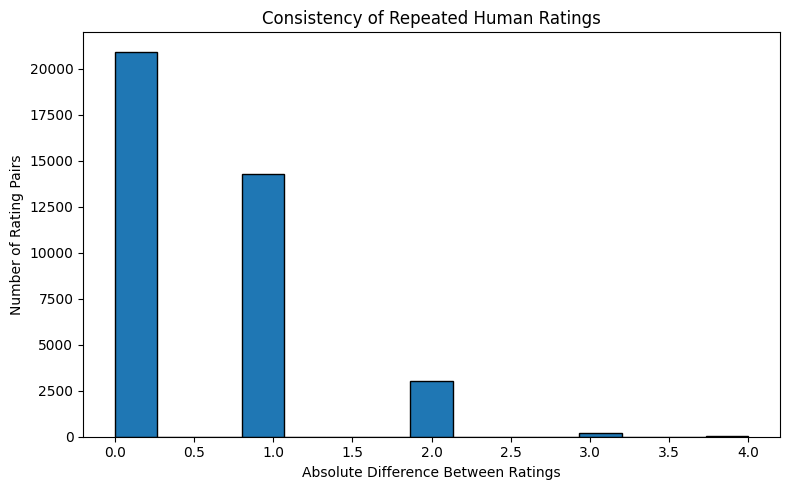

In [29]:
# Analyse repeated ratings

repeated_ratings = ratings_df[
    ratings_df["original Rating"].notna()
].copy()

current_ratings = repeated_ratings["Rating"].to_numpy()
original_ratings = repeated_ratings["original Rating"].to_numpy()

absolute_differences = np.abs(
    current_ratings - original_ratings
)

signed_differences = current_ratings - original_ratings

print("REPEATED HUMAN RATING ANALYSIS")

print("Number of paired ratings:", len(repeated_ratings))

print("Mean absolute difference:",
      round(float(absolute_differences.mean()), 4))

print("Mean signed difference:",
      round(float(signed_differences.mean()), 4))

print("Median absolute difference:",
      round(float(np.median(absolute_differences)), 4))

print("Correlation between repeated ratings:",
      round(float(np.corrcoef(
          current_ratings, original_ratings
      )[0, 1]), 4))

# Plot the distribution of rating differences

plt.figure(figsize=(8, 5))

plt.hist(absolute_differences, bins=15, edgecolor="black")

plt.xlabel("Absolute Difference Between Ratings")
plt.ylabel("Number of Rating Pairs")
plt.title("Consistency of Repeated Human Ratings")

plt.tight_layout()
plt.show()

## Residual Analysis

Residual analysis helps us understand the difference between actual human ratings and model predictions.

We use the predictions produced by the SVR model trained on HOG features.

A positive residual indicates that the model predicted a lower rating than the actual rating. A negative residual indicates that the model predicted a higher rating.

We examine the distribution of residuals and compare actual ratings with predicted ratings to identify possible patterns in the model's errors.

RESIDUAL ANALYSIS
Mean residual: 0.0509
Median residual: 0.0418
Standard deviation: 0.4472
Overestimation cases: 1011
Underestimation cases: 1189
Exact predictions: 0


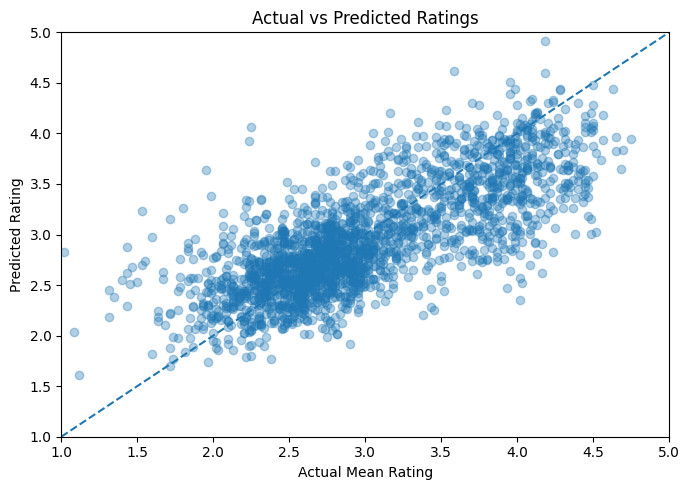

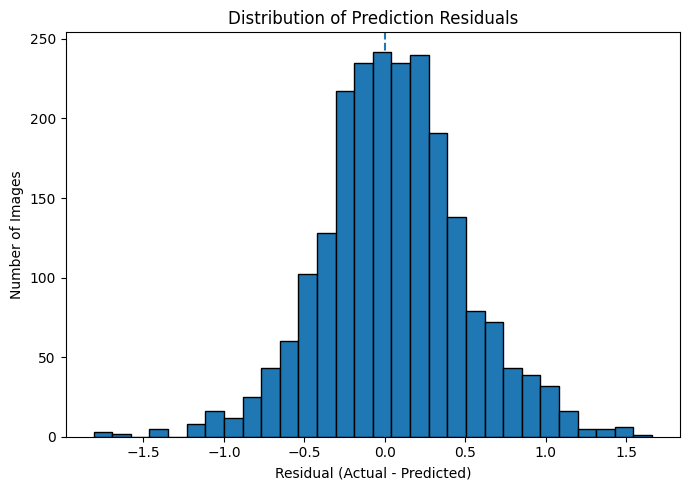

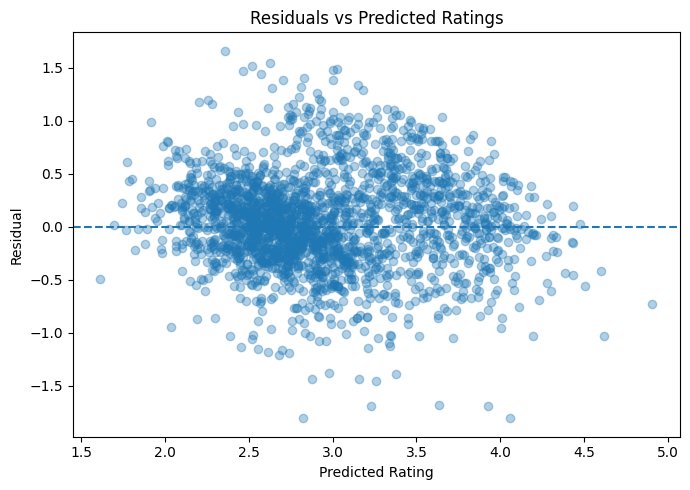

In [30]:
# Residual analysis for the best-performing model

best_predictions = model_predictions["SVR - HOG"]

residuals = y_test - best_predictions

print("RESIDUAL ANALYSIS")

print("Mean residual:", round(float(np.mean(residuals)), 4))
print("Median residual:", round(float(np.median(residuals)), 4))
print("Standard deviation:", round(float(np.std(residuals)), 4))

print("Overestimation cases:",
      int(np.sum(residuals < 0)))

print("Underestimation cases:",
      int(np.sum(residuals > 0)))

print("Exact predictions:",
      int(np.sum(residuals == 0)))

# Plot 1: Actual ratings vs predicted ratings

plt.figure(figsize=(7, 5))

plt.scatter(y_test, best_predictions, alpha=0.35)

plt.plot([1, 5], [1, 5], linestyle="--")

plt.xlabel("Actual Mean Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")

plt.xlim(1, 5)
plt.ylim(1, 5)

plt.tight_layout()
plt.show()

# Plot 2: Distribution of residuals

plt.figure(figsize=(7, 5))

plt.hist(residuals, bins=30, edgecolor="black")

plt.axvline(0, linestyle="--")

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Number of Images")
plt.title("Distribution of Prediction Residuals")

plt.tight_layout()
plt.show()

# Plot 3: Residuals vs predicted ratings

plt.figure(figsize=(7, 5))

plt.scatter(best_predictions, residuals, alpha=0.35)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Ratings")

plt.tight_layout()
plt.show()

## Analysis of Prediction Errors

Overall evaluation metrics do not explain which individual predictions are difficult for the model.

We therefore examine selected test examples from three categories:

1. Large overestimations, where the predicted rating is higher than the actual mean rating.
2. Large underestimations, where the predicted rating is lower than the actual mean rating.
3. High human-rating disagreement, where individual raters gave relatively different ratings to the same image.

For each example, we compare the actual mean rating, predicted rating, residual, and human-rating standard deviation.

This analysis helps identify cases where the model struggles and whether disagreement among human raters may contribute to prediction errors.

In [31]:
# Create a table of test-set prediction errors

test_errors = image_targets.iloc[test_indices].copy().reset_index(drop=True)

test_errors["Actual_Rating"] = y_test
test_errors["Predicted_Rating"] = best_predictions

test_errors["Residual"] = (
    test_errors["Actual_Rating"]
    - test_errors["Predicted_Rating"]
)

test_errors["Absolute_Error"] = np.abs(
    test_errors["Residual"]
)

# Select eight largest overestimations
overestimation_cases = (
    test_errors[test_errors["Residual"] < 0]
    .nsmallest(8, "Residual")
    .copy()
)

overestimation_cases["Category"] = "Overestimation"

# Select eight largest underestimations
underestimation_cases = (
    test_errors[test_errors["Residual"] > 0]
    .nlargest(8, "Residual")
    .copy()
)

underestimation_cases["Category"] = "Underestimation"

# Select eight images with highest human-rating disagreement
high_disagreement_cases = (
    test_errors.nlargest(8, "Rating_Std")
    .copy()
)

high_disagreement_cases["Category"] = "High Human Disagreement"

# Combine all selected examples
error_analysis = pd.concat([
    overestimation_cases,
    underestimation_cases,
    high_disagreement_cases
], ignore_index=True)

error_analysis = error_analysis[[
    "Filename",
    "Category",
    "Actual_Rating",
    "Predicted_Rating",
    "Residual",
    "Absolute_Error",
    "Rating_Std"
]]

print("SELECTED ERROR ANALYSIS EXAMPLES")
display(error_analysis.round(3))

print("\nNumber of selected examples:",
      len(error_analysis))

SELECTED ERROR ANALYSIS EXAMPLES


,Filename,Category,Actual_Rating,Predicted_Rating,Residual,Absolute_Error,Rating_Std
0,AM258.jpg,Overestimation,2.250,4.060,-1.810,1.810,0.728
1,AF1986.jpg,Overestimation,1.017,2.825,-1.809,1.809,0.129
2,AF1350.jpg,Overestimation,1.533,3.230,-1.696,1.696,0.566
3,AF868.jpg,Overestimation,2.233,3.925,-1.692,1.692,0.673
4,AM85.jpg,Overestimation,1.950,3.638,-1.688,1.688,0.746
5,AF1651.jpg,Overestimation,1.800,3.259,-1.459,1.459,0.659
6,AF1997.jpg,Overestimation,1.433,2.877,-1.443,1.443,0.593
7,AF1105.jpg,Overestimation,1.717,3.155,-1.438,1.438,0.783
8,AF1697.jpg,Underestimation,4.017,2.357,1.660,1.660,0.537
9,CM655.jpg,Underestimation,4.167,2.623,1.544,1.544,0.668



Number of selected examples: 24


## Learning Curve Analysis

A learning curve shows how model performance changes as the number of training examples increases.

We use the SVR model with HOG features and PCA dimensionality reduction.

The model is evaluated using the predefined five-fold cross-validation splits at different training-set sizes.

We compare training and validation errors to understand how well the model learns from the available data and whether additional training examples may improve its performance.

Generating learning curves...

LEARNING CURVE RESULTS


,Training Samples,Training MAE,Validation MAE,Validation MAE Std
0,880,0.0901,0.3960,0.0141
1,1760,0.0902,0.3654,0.0105
2,2640,0.0902,0.3533,0.0110
3,3520,0.0901,0.3484,0.0095
4,4400,0.0900,0.3412,0.0083



Learning curve computation time: 166.66 seconds


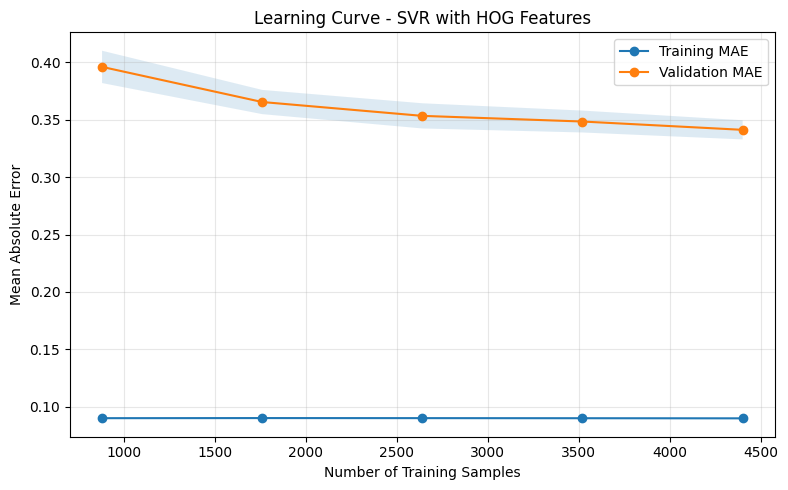

In [32]:
# Generate learning curves for SVR with HOG features

learning_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=100, random_state=42)),
    ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
])

print("Generating learning curves...")

start_time = time.time()

train_sizes, train_scores, validation_scores = learning_curve(
    learning_model,
    X_hog,
    y,
    cv=cv_splits,
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

learning_time = time.time() - start_time

# Convert negative MAE scores into positive errors

train_errors = -train_scores
validation_errors = -validation_scores

train_mean = train_errors.mean(axis=1)
train_std = train_errors.std(axis=1)

validation_mean = validation_errors.mean(axis=1)
validation_std = validation_errors.std(axis=1)

learning_results = pd.DataFrame({
    "Training Samples": train_sizes,
    "Training MAE": train_mean,
    "Validation MAE": validation_mean,
    "Validation MAE Std": validation_std
})

print("\nLEARNING CURVE RESULTS")
display(learning_results.round(4))

print("\nLearning curve computation time:",
      round(learning_time, 2), "seconds")

# Plot learning curves

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training MAE"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation MAE"
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Mean Absolute Error")
plt.title("Learning Curve - SVR with HOG Features")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Comparing PCA and Feature Selection

Dimensionality reduction can be performed using different techniques.

In this experiment, we compare:

1. **PCA:** transforms the original HOG features into 100 principal components.
2. **SelectKBest:** selects the 100 most relevant original HOG features using the F-test.

Both approaches use the same SVR algorithm and hyperparameters.

We evaluate them using the five predefined cross-validation folds. Feature reduction is performed inside each pipeline, ensuring that feature selection and PCA are fitted only on the corresponding training fold.

We also compare training time and saved model size to understand the computational cost of each approach.

In [33]:
# Compare PCA and SelectKBest with 100 features

reduction_models = {
    "PCA - 100 components": Pipeline([
        ("scaler", StandardScaler()),
        ("reduction", PCA(n_components=100, random_state=42)),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),

    "SelectKBest - 100 features": Pipeline([
        ("selection", SelectKBest(
            score_func=f_regression,
            k=100
        )),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ])
}

reduction_cv_results = []

for model_name, model in reduction_models.items():

    print(f"\nEvaluating {model_name}...")

    for fold_number, (train_idx, test_idx) in enumerate(
        cv_splits, start=1
    ):

        model.fit(X_hog[train_idx], y[train_idx])

        predictions = model.predict(X_hog[test_idx])

        reduction_cv_results.append({
            "Method": model_name,
            "Fold": fold_number,
            "MAE": mean_absolute_error(y[test_idx], predictions),
            "RMSE": np.sqrt(mean_squared_error(
                y[test_idx], predictions
            )),
            "R2": r2_score(y[test_idx], predictions)
        })

        print(f"Fold {fold_number} completed.")

reduction_cv_df = pd.DataFrame(reduction_cv_results)

print("\nCROSS-VALIDATION COMPARISON")

display(
    reduction_cv_df.groupby("Method")[
        ["MAE", "RMSE", "R2"]
    ].agg(["mean", "std"]).round(4)
)

# Fit both methods on the main training split
# and measure training time and saved model size.

reduction_final_results = []

for model_name, model in reduction_models.items():

    print(f"\nTraining final {model_name} model...")

    start_time = time.time()

    model.fit(X_hog_train, y_train)

    training_time = time.time() - start_time

    predictions = model.predict(X_hog_test)

    model_path = "/content/" + model_name.replace(
        " ", "_"
    ).replace("-", "") + ".joblib"

    joblib.dump(model, model_path)

    model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

    reduction_final_results.append({
        "Method": model_name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(
            y_test, predictions
        )),
        "Test R2": r2_score(y_test, predictions),
        "Training Time (seconds)": training_time,
        "Model Size (MB)": model_size_mb
    })

print("\nFINAL REDUCTION METHOD COMPARISON")

display(
    pd.DataFrame(reduction_final_results).round(4)
)


Evaluating PCA - 100 components...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

Evaluating SelectKBest - 100 features...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

CROSS-VALIDATION COMPARISON


MAE            RMSE              R2        
                              mean     std    mean     std    mean     std
Method                                                                    
PCA - 100 components        0.3412  0.0093  0.4496  0.0094  0.5726  0.0192
SelectKBest - 100 features  0.4285  0.0165  0.5586  0.0211  0.3395  0.0532


Training final PCA - 100 components model...

Training final SelectKBest - 100 features model...

FINAL REDUCTION METHOD COMPARISON


,Method,Test MAE,Test RMSE,Test R2,Training Time (seconds),Model Size (MB)
0,PCA - 100 components,0.3442,0.4500,0.5599,8.3843,5.3735
1,SelectKBest - 100 features,0.4312,0.5561,0.3279,1.8953,2.3073


## Saving the Final Model

Based on the model comparison and cross-validation experiments, we select SVR with HOG features and PCA dimensionality reduction.

The final pipeline contains:

1. StandardScaler for feature scaling.
2. PCA with 100 components for dimensionality reduction.
3. Support Vector Regression with an RBF kernel.

We save the trained pipeline using Joblib so that it can be reused without training the model again.

The saved model will be used to predict ratings for previously unseen images.

In [34]:
# Save the selected final model

final_model = trained_models["SVR - HOG"]

model_file = "/content/final_svr_hog_model.joblib"

joblib.dump(final_model, model_file)

print("Final model saved successfully!")
print("Model location:", model_file)

print("Model size:",
      round(os.path.getsize(model_file) / (1024 ** 2), 2),
      "MB")

Final model saved successfully!
Model location: /content/final_svr_hog_model.joblib
Model size: 5.37 MB


## Predicting Ratings for Unseen Images

We now create a prediction function for new face images.

The function performs the same preprocessing and HOG feature extraction steps used during model training. It then passes the extracted features through the saved machine learning pipeline.

The model returns a continuous rating estimate. The result is restricted to the original dataset's rating range of 1 to 5.

These predictions are experimental estimates of aggregate human ratings. They are not objective assessments of appearance and should not be used to judge individuals.

In [35]:
# Load the saved model

loaded_model = joblib.load(model_file)

# Function to extract HOG features from a new image

def extract_hog_features(image_path):

    with Image.open(image_path) as img:

        img = img.convert("L")
        img = img.resize((128, 128))

        image_array = np.array(img)

    features = hog(
        image_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features.reshape(1, -1).astype(np.float32)


# Function to predict a rating

def predict_rating(image_path):

    features = extract_hog_features(image_path)

    raw_prediction = float(
        loaded_model.predict(features)[0]
    )

    predicted_rating = np.clip(raw_prediction, 1, 5)

    print("Predicted mean human rating:",
          round(float(predicted_rating), 3))

    print("Prediction warning: This is an experimental estimate,")
    print("not an objective or guaranteed rating.")

    return float(predicted_rating)


# Test the function using one image from the test set

sample_image_path = str(
    images_path / test_filenames[0]
)

print("Testing prediction on:", test_filenames[0])

sample_prediction = predict_rating(sample_image_path)

Testing prediction on: CM423.jpg
Predicted mean human rating: 2.665
Prediction warning: This is an experimental estimate,
not an objective or guaranteed rating.


## Prediction Pipeline Validation

We compare the prediction generated by our reusable function with the prediction previously obtained during model evaluation.

Both predictions should be approximately equal because they use the same trained model and feature extraction process.

In [36]:
# Validate the prediction pipeline

original_prediction = float(
    model_predictions["SVR - HOG"][0]
)

new_prediction = sample_prediction

difference = abs(original_prediction - new_prediction)

print("Original model prediction:",
      round(original_prediction, 6))

print("Reusable function prediction:",
      round(new_prediction, 6))

print("Absolute difference:",
      round(difference, 8))

if difference < 1e-5:
    print("\nPrediction pipeline validated successfully!")
else:
    print("\nPrediction mismatch detected. Check preprocessing.")

Original model prediction: 2.665354
Reusable function prediction: 2.665354
Absolute difference: 5e-08

Prediction pipeline validated successfully!


## Project Limitations

Although the model produces useful estimates, several limitations should be considered.

1. **Subjective ratings:** Human ratings represent personal opinions and may vary between individuals and repeated evaluations.

2. **Dataset limitations:** The model was trained using the SCUT-FBP5500 dataset. Its performance on images collected under different conditions or from other populations has not been established.

3. **Feature limitations:** HOG features capture local image gradients and structural information but may not represent every visual factor considered by human raters.

4. **Prediction errors:** The model sometimes overestimates low ratings and underestimates high ratings. Its predictions should therefore not be treated as exact values.

5. **Subject-level validation:** The available dataset splits do not provide verified subject identity groups. Although exact duplicate images were not found, near-duplicate images and subject overlap cannot be completely ruled out.

6. **Fairness evaluation:** This project does not establish that prediction errors are equal across demographic groups. No sensitive characteristics are inferred from face images, and further evaluation would require suitable, verified metadata and sufficient samples.

7. **Limited generalisation:** The model has been evaluated on predefined dataset partitions. Its performance on external datasets and real-world images remains unknown.

8. **Model-selection limitation:** The predefined test set was inspected during several model and feature-comparison experiments. Therefore, it was not kept completely untouched until the final evaluation. The reported test metrics may be somewhat optimistic as estimates of generalisation. The five-fold cross-validation results provide an additional assessment of model stability.

The model is intended only as an educational machine learning experiment for estimating aggregate human ratings. It should not be used to determine a person's attractiveness, worth, suitability, or opportunities.

## Reproducibility and Project Files

To make the project easier to review and reproduce, we save the important experimental results, dataset split information, model file, and software environment details.

The exported files include model comparison results, cross-validation results, feature dimensionality experiments, target comparisons, learning-curve results, and selected prediction errors.

The saved model and prediction function can also be reused without repeating the complete training process.

In [48]:
# Create a folder for project outputs

import shutil
import platform

output_folder = Path("/content/Neural_Ninjas_Project")
output_folder.mkdir(exist_ok=True)

# Save the trained model
joblib.dump(
    final_model,
    output_folder / "final_svr_hog_model.joblib"
)

# Save experimental result tables
result_tables = {
    "model_comparison.csv": results_df,
    "cross_validation_results.csv": cv_results_df,
    "feature_dimension_comparison.csv": dimension_results_df,
    "target_comparison.csv": median_target_results,
    "feature_reduction_cv.csv": reduction_cv_df,
    "learning_curve_results.csv": learning_results,
    "prediction_error_analysis.csv": error_analysis
}

for filename, dataframe in result_tables.items():
    dataframe.to_csv(
        output_folder / filename,
        index=False
    )

# Save image-level target information
image_targets.to_csv(
    output_folder / "image_rating_targets.csv",
    index=False
)

# Save the predefined train-test split manifest
split_manifest = pd.DataFrame({
    "Filename": train_filenames + test_filenames,
    "Split": (
        ["Train"] * len(train_filenames)
        + ["Test"] * len(test_filenames)
    )
})

split_manifest.to_csv(
    output_folder / "train_test_split_manifest.csv",
    index=False
)

# Save five-fold split information
fold_manifest = []

for fold_number, fold in enumerate(fold_splits, start=1):

    for filename in fold["train"]["Filename"]:
        fold_manifest.append({
            "Filename": filename,
            "Fold": fold_number,
            "Split": "Train"
        })

    for filename in fold["test"]["Filename"]:
        fold_manifest.append({
            "Filename": filename,
            "Fold": fold_number,
            "Split": "Test"
        })

pd.DataFrame(fold_manifest).to_csv(
    output_folder / "five_fold_split_manifest.csv",
    index=False
)

# Save software environment information
environment_text = f"""
Python: {platform.python_version()}
NumPy: {np.__version__}
Pandas: {pd.__version__}
Scikit-learn: {sklearn.__version__}
Scikit-image: {skimage.__version__}
Pillow: {Image.__version__ if hasattr(Image, '__version__') else 'See Pillow package metadata'}

Main model: SVR with HOG features
Image size: 128 x 128
HOG orientations: 9
Pixels per cell: 8 x 8
Cells per block: 2 x 2
PCA components: 100
SVR kernel: RBF
SVR C: 10
SVR epsilon: 0.1
"""

with open(output_folder / "environment.txt", "w") as file:
    file.write(environment_text)

print("Project files exported successfully!")
print("Output folder:", output_folder)

print("\nExported files:")
for file in sorted(output_folder.iterdir()):
    print("-", file.name)

Project files exported successfully!
Output folder: /content/Neural_Ninjas_Project

Exported files:
- README.md
- cross_validation_results.csv
- environment.txt
- feature_dimension_comparison.csv
- feature_reduction_cv.csv
- final_svr_hog_model.joblib
- five_fold_split_manifest.csv
- image_rating_targets.csv
- learning_curve_results.csv
- model_comparison.csv
- models
- prediction_error_analysis.csv
- requirements.txt
- results
- target_comparison.csv
- train_test_split_manifest.csv


## Optional Testing with a New Image

In this section, the trained model is tested using an image uploaded directly from a computer.

The prediction function extracts HOG features from the uploaded image and uses the saved SVR model to estimate its rating.

This test demonstrates that the prediction pipeline can process an image outside the dataset.

Since a single uploaded image does not have a known human rating, evaluation metrics such as MAE, RMSE, and R² cannot be calculated for it.

The predicted score is an experimental estimate of aggregate human ratings and should not be treated as an objective judgement.

In [ ]:

from google.colab import files

uploaded = files.upload()

new_image_path = list(uploaded.keys())[0]

print("Image uploaded successfully:", new_image_path)


In [ ]:

# Predict the rating for the uploaded image

new_prediction = predict_rating(new_image_path)

print("\nFinal Prediction")
print("Predicted Human Rating:", round(new_prediction, 3), "/ 5")


## Final Evaluation Using the Predefined Test Set

In this section, the saved SVR model is loaded again and evaluated on the predefined test set containing 2,200 images.

The model predictions are compared with the actual mean human ratings using four regression evaluation metrics:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score
- Median Absolute Error

This evaluation also checks whether the saved model reproduces the results obtained during the earlier model comparison.

Since this predefined test set was already inspected during model-selection experiments, this is a reproducibility check rather than a completely independent final evaluation.

In [41]:

# Load the saved model
final_loaded_model = joblib.load(model_file)

# Predict ratings for all test images
final_test_predictions = final_loaded_model.predict(X_hog_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, final_test_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_test_predictions))
final_r2 = r2_score(y_test, final_test_predictions)
final_median_ae = median_absolute_error(y_test, final_test_predictions)

print("FINAL TEST SET EVALUATION")
print("-------------------------")
print("Number of test images:", len(y_test))
print("MAE:", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))
print("Median Absolute Error:", round(final_median_ae, 4))


FINAL TEST SET EVALUATION
-------------------------
Number of test images: 2200
MAE: 0.3442
RMSE: 0.45
R2 Score: 0.5599
Median Absolute Error: 0.2695


## Saving Final Evaluation Results

The final evaluation metrics are saved in a CSV file for documentation and reproducibility.

In [42]:

final_evaluation = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score", "Median Absolute Error"],
    "Value": [final_mae, final_rmse, final_r2, final_median_ae]
})

evaluation_file = "/content/Neural_Ninjas_Project/final_evaluation.csv"
final_evaluation.to_csv(evaluation_file, index=False)

print("Final evaluation results saved successfully!")
print(final_evaluation)


Final evaluation results saved successfully!
                  Metric     Value
0                    MAE  0.344235
1                   RMSE  0.450047
2               R2 Score  0.559864
3  Median Absolute Error  0.269515


## Final Conclusion

This project explored the use of classical machine learning techniques to estimate average human ratings from face images using the SCUT-FBP5500 dataset.

The dataset was audited and found to contain 5,500 valid images, each associated with 60 human ratings. The mean of the ratings was selected as the primary prediction target after comparing it with the median.

Two image representations were investigated: Histogram of Oriented Gradients (HOG) and RGB colour histograms. HOG features provided better predictive performance across the evaluated models.

Four regression algorithms were compared: Linear Regression, Ridge Regression, Random Forest Regression, and Support Vector Regression. SVR using HOG features achieved the best initial test-set performance, with an MAE of 0.3442 and an R² score of 0.5599.

Five-fold cross-validation produced an average MAE of 0.3412 and an average R² score of 0.5726 for the SVR-HOG model. Further experiments showed that PCA with 100 components performed better than selecting 100 individual HOG features for this SVR configuration.

Residual and error analyses revealed that the model sometimes overestimates low ratings and underestimates high ratings. The learning curve also indicated that validation performance improved as more training samples were used.

Finally, the trained model was saved and a reusable prediction function was developed. Its output was successfully validated against the original model prediction.

Overall, the project demonstrates how handcrafted image features and classical machine learning algorithms can be applied to an image-based regression problem. However, the predictions remain estimates of subjective aggregate human ratings and must be interpreted with the limitations of the dataset and evaluation methodology in mind.

One limitation of the evaluation is that the predefined test set was also inspected during model-comparison experiments. Therefore, its performance metrics should be interpreted alongside the five-fold cross-validation results rather than as a completely independent estimate of generalisation.

The project demonstrates the application of classical machine learning and handcrafted image features to a supervised image-regression task while recognising the subjective nature and limitations of human ratings.

## Creating the Project README

A README file explains the project to anyone visiting the GitHub repository. It includes the problem statement, dataset, machine learning methods, evaluation results, project structure, and limitations.

In [52]:

readme_content = """
# Estimating Human Ratings from Face Images

### Machine Learning Project | Neural Ninjas | Batch A3

## 1. Project Overview

This project uses classical machine learning techniques to estimate
the average human rating associated with a face image.

The project uses the SCUT-FBP5500 dataset and treats the task as
a supervised regression problem.

The predicted score represents an aggregate human rating. It is
not an objective measure of beauty, personal worth, or suitability.

## 2. Dataset

- Dataset: SCUT-FBP5500
- Number of images: 5,500
- Ratings per image: 60
- Rating scale: 1 to 5
- Task: Regression
- Target: Mean human rating

The dataset is not included in this repository. Users must obtain
it separately and follow its applicable terms of use.

## 3. Feature Extraction

Two handcrafted image representations were explored:

- HOG (Histogram of Oriented Gradients): 8,100 features
- RGB Colour Histogram: 96 features

HOG features were more effective for the final model.

## 4. Machine Learning Models

The following classical regression approaches were compared:

- Linear Regression
- Ridge Regression
- Random Forest Regressor
- Support Vector Regression (SVR)
- Dummy Regressor as a baseline

PCA and feature selection were also compared.

No deep learning models were used.

## 5. Final Model

The selected model is Support Vector Regression (SVR)
using HOG features and PCA dimensionality reduction.

## 6. Final Evaluation Results

Evaluation on the predefined 2,200-image test set:

| Metric | Result |
|---|---:|
| MAE | 0.3442 |
| RMSE | 0.4500 |
| R2 Score | 0.5599 |
| Median Absolute Error | 0.2695 |

Five-fold cross-validation results:

- Mean MAE: 0.3412
- Mean RMSE: 0.4496
- Mean R2 Score: 0.5726

## 7. Running the Project

1. Download the SCUT-FBP5500 dataset separately.
2. Open the Jupyter notebook in Google Colab.
3. Install the required Python libraries if necessary.
4. Set the dataset path according to the notebook.
5. Run the notebook cells in order.

The saved model can also be used through the prediction
function provided in the notebook.

## 8. Limitations and Responsible Use

- Human ratings are subjective and may vary between raters.
- The model may overestimate lower ratings and underestimate higher ratings.
- Generalisation to images outside this dataset has not been established.
- Verified subject identity groups were not available for a subject-wise split.
- Exact duplicate images were not found, but near-duplicate images and subject overlap cannot be completely ruled out.
- Fairness across demographic groups has not been established.
- The predefined test set was inspected during model-comparison experiments, so its metrics may be somewhat optimistic.
- The model must not be used to make decisions about individuals.

This project is an educational machine learning experiment. Its predictions are estimates of aggregate human ratings, not objective judgements about people.

## 9. Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Scikit-image
- OpenPyXL
- Joblib
- Google Colab

## 10. Project Structure

- `ML_Project.ipynb`: Complete project notebook
- `models/`: Saved trained model
- `results/`: Evaluation tables, split manifests, and visualisations
- `README.md`: Project overview and documentation
- `requirements.txt`: Required Python libraries
- `environment.txt`: Recorded software environment
"""

readme_path = "/content/Neural_Ninjas_Project/README.md"

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Location:", readme_path)


README.md created successfully!
Location: /content/Neural_Ninjas_Project/README.md


## Organising the Project Files

The project files are arranged into separate folders to make the GitHub repository easier to navigate and understand.

In [45]:

import os
import shutil

project_path = "/content/Neural_Ninjas_Project"

# Create project folders
results_path = os.path.join(project_path, "results")
models_path = os.path.join(project_path, "models")

os.makedirs(results_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

# Move the trained model
model_source = os.path.join(project_path, "final_svr_hog_model.joblib")
if os.path.exists(model_source):
    shutil.move(
        model_source,
        os.path.join(models_path, "final_svr_hog_model.joblib")
    )

# Move CSV result files
for filename in os.listdir(project_path):
    if filename.endswith(".csv"):
        shutil.move(
            os.path.join(project_path, filename),
            os.path.join(results_path, filename)
        )

# Display the organised structure
print("Project organised successfully!\n")

for folder, subfolders, files_list in os.walk(project_path):
    level = folder.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level
    print(indent + os.path.basename(folder) + "/")

    for filename in files_list:
        print(" " * 4 * (level + 1) + filename)


Project organised successfully!

Neural_Ninjas_Project/
    environment.txt
    README.md
    results/
        learning_curve_results.csv
        target_comparison.csv
        cross_validation_results.csv
        feature_dimension_comparison.csv
        model_comparison.csv
        image_rating_targets.csv
        final_evaluation.csv
        feature_reduction_cv.csv
        train_test_split_manifest.csv
        five_fold_split_manifest.csv
        prediction_error_analysis.csv
    models/
        final_svr_hog_model.joblib


## Creating the Requirements File

This file lists the Python libraries required to run the project. It helps another person install the same basic dependencies before executing the notebook.

In [46]:

requirements = """
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scikit-image==0.25.2
matplotlib
seaborn
Pillow
openpyxl
joblib
gdown
"""

requirements_path = "/content/Neural_Ninjas_Project/requirements.txt"

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write(requirements.strip() + "\n")

print("requirements.txt created successfully!")
print("\nRequired libraries:")
print(requirements)


requirements.txt created successfully!

Required libraries:

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scikit-image==0.25.2
matplotlib
seaborn
Pillow
openpyxl
joblib
gdown



## Saving Project Visualisations

The important graphs generated during the project are saved in the results folder.

These visualisations help explain the dataset, human-rating disagreement, model predictions, prediction errors, learning behaviour, and the effect of feature dimensionality on model performance.

The saved plots can be viewed separately without running the complete notebook.

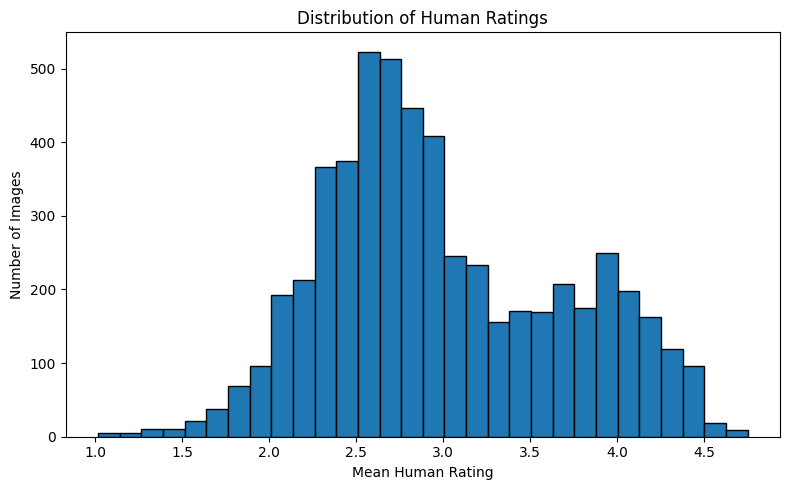

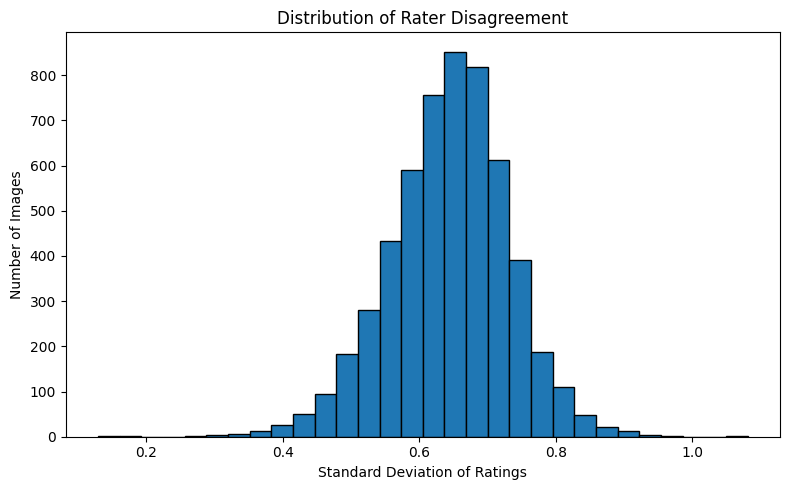

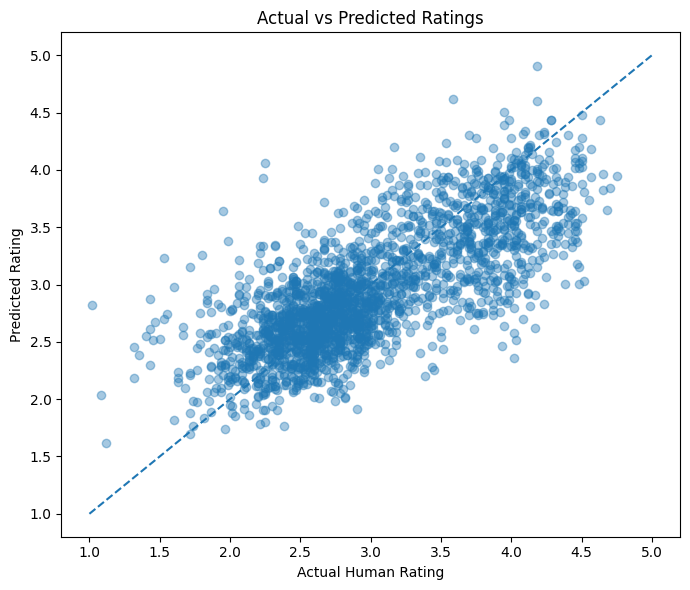

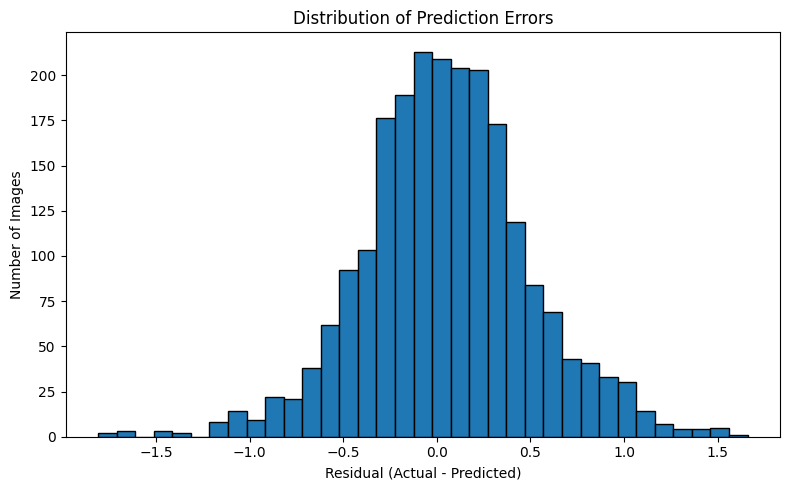

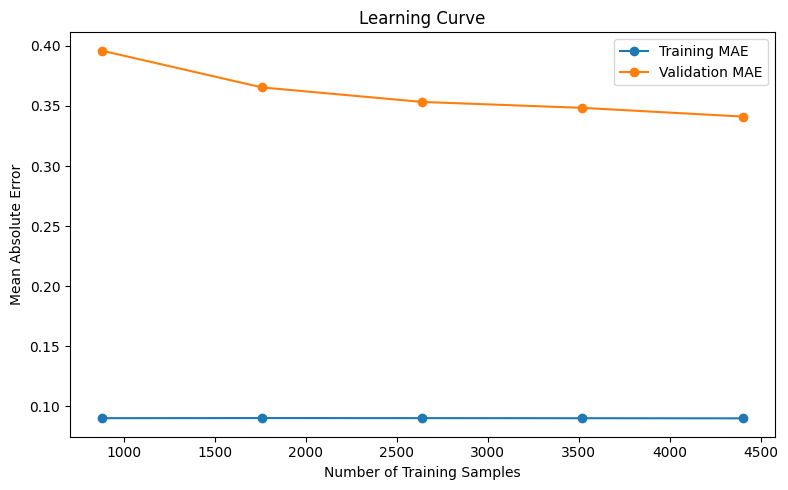

All five project plots saved successfully!
Plot folder: /content/Neural_Ninjas_Project/results/plots
Number of plots: 5


In [47]:

import os
import matplotlib.pyplot as plt

plots_path = "/content/Neural_Ninjas_Project/results/plots"
os.makedirs(plots_path, exist_ok=True)

# 1. Human rating distribution
plt.figure(figsize=(8, 5))
plt.hist(image_targets["Mean_Rating"], bins=30, edgecolor="black")
plt.xlabel("Mean Human Rating")
plt.ylabel("Number of Images")
plt.title("Distribution of Human Ratings")
plt.tight_layout()
plt.savefig(os.path.join(plots_path, "rating_distribution.png"), dpi=150)
plt.show()

# 2. Rater disagreement distribution
plt.figure(figsize=(8, 5))
plt.hist(image_targets["Rating_Std"], bins=30, edgecolor="black")
plt.xlabel("Standard Deviation of Ratings")
plt.ylabel("Number of Images")
plt.title("Distribution of Rater Disagreement")
plt.tight_layout()
plt.savefig(os.path.join(plots_path, "rater_disagreement.png"), dpi=150)
plt.show()

# 3. Actual vs predicted ratings
plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_test_predictions, alpha=0.4)
plt.plot([1, 5], [1, 5], linestyle="--")
plt.xlabel("Actual Human Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")
plt.tight_layout()
plt.savefig(os.path.join(plots_path, "actual_vs_predicted.png"), dpi=150)
plt.show()

# 4. Residual distribution
final_residuals = y_test - final_test_predictions

plt.figure(figsize=(8, 5))
plt.hist(final_residuals, bins=35, edgecolor="black")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Number of Images")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.savefig(os.path.join(plots_path, "residual_distribution.png"), dpi=150)
plt.show()

# 5. Learning curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training MAE")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation MAE")
plt.xlabel("Number of Training Samples")
plt.ylabel("Mean Absolute Error")
plt.title("Learning Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_path, "learning_curve.png"), dpi=150)
plt.show()

print("All five project plots saved successfully!")
print("Plot folder:", plots_path)
print("Number of plots:", len(os.listdir(plots_path)))


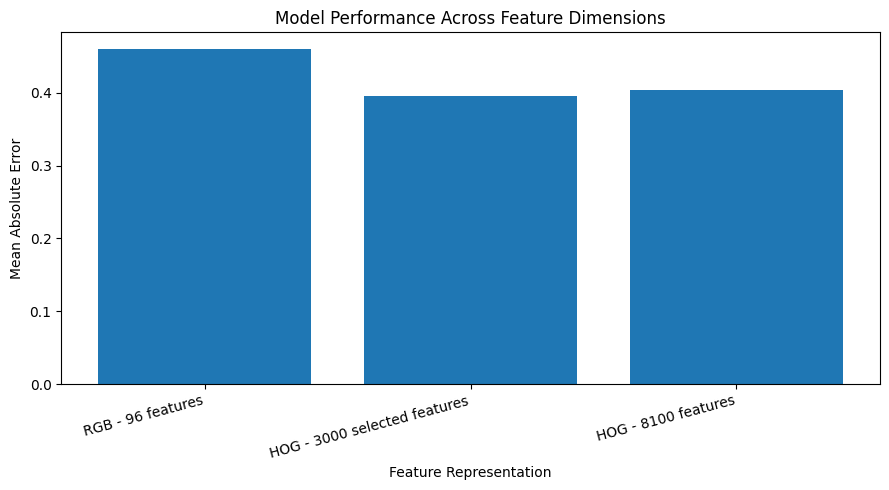

Feature dimension comparison plot saved successfully!


In [49]:

# 6. Model performance across feature dimensions

plt.figure(figsize=(9, 5))

plt.bar(
    dimension_results_df["Representation"],
    dimension_results_df["MAE"]
)

plt.xlabel("Feature Representation")
plt.ylabel("Mean Absolute Error")
plt.title("Model Performance Across Feature Dimensions")
plt.xticks(rotation=15, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(plots_path, "feature_dimension_comparison.png"),
    dpi=150
)

plt.show()

print("Feature dimension comparison plot saved successfully!")


## Creating the Final Project Archive

All project files are now organised into their respective folders. In this final step, we create a ZIP archive containing the README, requirements, saved model, experimental results, visualisations, and environment information.

In [50]:

import os
import shutil

project_path = "/content/Neural_Ninjas_Project"
zip_path = "/content/Neural_Ninjas_Project.zip"

# Remove the previous archive, if it exists
if os.path.exists(zip_path):
    os.remove(zip_path)

# Create the final archive
shutil.make_archive(
    "/content/Neural_Ninjas_Project",
    "zip",
    "/content",
    "Neural_Ninjas_Project"
)

print("Final project ZIP created successfully!")
print("ZIP location:", zip_path)

print("\nFinal project structure:")

for folder, subfolders, files_list in os.walk(project_path):
    level = folder.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level

    print(indent + os.path.basename(folder) + "/")

    for filename in sorted(files_list):
        print(" " * 4 * (level + 1) + filename)


Final project ZIP created successfully!
ZIP location: /content/Neural_Ninjas_Project.zip

Final project structure:
Neural_Ninjas_Project/
    README.md
    cross_validation_results.csv
    environment.txt
    feature_dimension_comparison.csv
    feature_reduction_cv.csv
    final_svr_hog_model.joblib
    five_fold_split_manifest.csv
    image_rating_targets.csv
    learning_curve_results.csv
    model_comparison.csv
    prediction_error_analysis.csv
    requirements.txt
    target_comparison.csv
    train_test_split_manifest.csv
    results/
        cross_validation_results.csv
        feature_dimension_comparison.csv
        feature_reduction_cv.csv
        final_evaluation.csv
        five_fold_split_manifest.csv
        image_rating_targets.csv
        learning_curve_results.csv
        model_comparison.csv
        prediction_error_analysis.csv
        target_comparison.csv
        train_test_split_manifest.csv
        plots/
            actual_vs_predicted.png
            feature_d

In [51]:

from google.colab import files

files.download("/content/Neural_Ninjas_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>